In [1]:
# 1. Установка зависимостей и импорты
# В Colab обычно PyTorch, torchvision, matplotlib уже установлены.
# При необходимости раскомментируйте:
# !pip install -q kaggle scikit-learn seaborn tqdm

import os
import glob
import zipfile
import random
import copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, random_split
from PIL import Image
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns
from tqdm.auto import tqdm

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')


Device: cuda


In [2]:
# 2. Подключение Google Drive и (при необходимости) скачивание SUIM
!pip install -q kaggle

from google.colab import drive
drive.mount('/content/drive')

# Датасет уже распакован? Тогда скачивание не требуется.
# По результатам проверки структура находится в DATA_ROOT/SUIM/.
BASE_ROOT = '/content/drive/MyDrive/Colab Notebooks/DL/data/SUIM'
os.makedirs(BASE_ROOT, exist_ok=True)

# ВАЖНО: не записывайте API key прямо в ноутбук.
# Если датасет ещё не скачан, задайте KAGGLE_USERNAME и KAGGLE_KEY
# через getpass (ввод ключа будет скрыт), затем выполните скачивание.
from getpass import getpass

DOWNLOAD_DATASET = False  # Поставьте True только если нужно скачать заново.

if DOWNLOAD_DATASET:
    import os
    os.environ['KAGGLE_USERNAME'] = 'liubovsobol'
    os.environ['KAGGLE_KEY'] = 'KGAT_4a472d6e2d57ccd42daac3eda084531f'
    !kaggle datasets download -d wxli408/suim-dataset -p /content
    with zipfile.ZipFile('/content/suim-dataset.zip', 'r') as zip_ref:
        zip_ref.extractall(BASE_ROOT)
    print('Архив распакован в:', BASE_ROOT)
else:
    print('Повторное скачивание пропущено: используем уже загруженный датасет.')


Mounted at /content/drive
Повторное скачивание пропущено: используем уже загруженный датасет.


In [3]:
# 2а. Если архив уже скачан в текущую сессию, его можно распаковать так.
# Если датасет уже распакован на Google Drive, эту ячейку повторно запускать не нужно.
zip_path = '/content/suim-dataset.zip'
if os.path.isfile(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(BASE_ROOT)
    print('Датасет распакован в:', BASE_ROOT)
else:
    print('Архив в /content не найден — это нормально, если датасет уже распакован на Google Drive.')


Архив в /content не найден — это нормально, если датасет уже распакован на Google Drive.


In [5]:
# 2в. Автоматически определяем корневую папку SUIM.
# В архиве могла появиться дополнительная вложенность BASE_ROOT/SUIM.
candidates = [BASE_ROOT, os.path.join(BASE_ROOT, 'SUIM')]
DATA_ROOT = None

for candidate in candidates:
    required = [
        os.path.join(candidate, 'train_val', 'images'),
        os.path.join(candidate, 'train_val', 'masks'),
        os.path.join(candidate, 'TEST', 'images'),
        os.path.join(candidate, 'TEST', 'masks'),
    ]
    if all(os.path.isdir(p) for p in required):
        DATA_ROOT = candidate
        break

if DATA_ROOT is None:
    raise FileNotFoundError(
        'Не найдена ожидаемая структура SUIM: train_val/images, train_val/masks, TEST/images, TEST/masks. '
        'Посмотрите дерево папок в предыдущей ячейке.'
    )

train_img_dir = os.path.join(DATA_ROOT, 'train_val', 'images')
train_mask_dir = os.path.join(DATA_ROOT, 'train_val', 'masks')
test_img_dir = os.path.join(DATA_ROOT, 'TEST', 'images')
test_mask_dir = os.path.join(DATA_ROOT, 'TEST', 'masks')

print('Используем DATA_ROOT:', DATA_ROOT)
for name, path in [
    ('Train images', train_img_dir), ('Train masks', train_mask_dir),
    ('Test images', test_img_dir), ('Test masks', test_mask_dir)
]:
    print(f'{name}: существует={os.path.isdir(path)}')


Используем DATA_ROOT: /content/drive/MyDrive/Colab Notebooks/DL/data/SUIM/SUIM
Train images: существует=True
Train masks: существует=True
Test images: существует=True
Test masks: существует=True


Папка изображений: /content/drive/MyDrive/Colab Notebooks/DL/data/SUIM/SUIM/train_val/images
Папка масок:       /content/drive/MyDrive/Colab Notebooks/DL/data/SUIM/SUIM/train_val/masks
Изображений найдено: 1525
Файлов масок найдено: 1506
Пар изображение-маска: 1506
Внимание: без маски 19 изображений. Примеры: ['n_l_64_', 'w_r_82_', 'w_r_83_', 'w_r_85_', 'w_r_86_']
Папка изображений: /content/drive/MyDrive/Colab Notebooks/DL/data/SUIM/SUIM/TEST/images
Папка масок:       /content/drive/MyDrive/Colab Notebooks/DL/data/SUIM/SUIM/TEST/masks
Изображений найдено: 110
Файлов масок найдено: 110
Пар изображение-маска: 110

Обучающих примеров: 1506
Тестовых примеров: 110
Форма изображения: (3, 256, 256)
Форма маски: (256, 256)
Уникальные классы: [0, 1, 2, 4]
Минимальная/максимальная метка: 0 4
Наиболее частые RGB-цвета исходной маски:
[0, 0, 0] пикселей: 152482
[0, 255, 255] пикселей: 66776
[255, 255, 255] пикселей: 64339
[0, 0, 255] пикселей: 23603


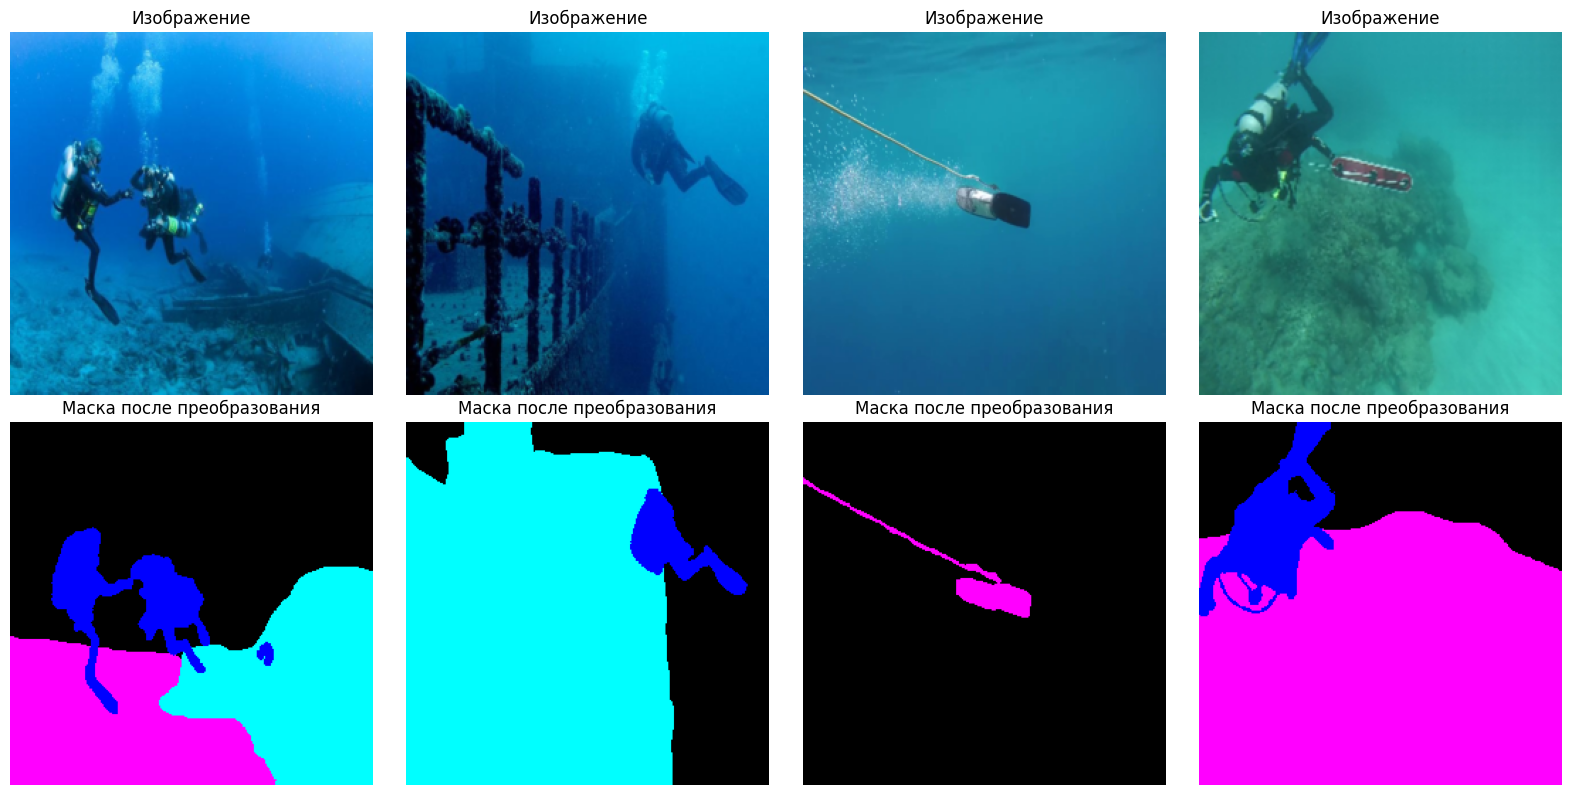

In [6]:
# 3. Классы и загрузка SUIM
# Сохраняем принятую в исходном варианте работы схему объединения:
# 0: фон/вода, 1: дайверы, 2: обломки, 3: рыбы,
# 4: объединённый класс (растения + роботы + рифы + дно).
NUM_CLASSES = 5

# Цвета только для визуализации уже преобразованной карты классов.
CLASS_COLORS = np.array([
    [0, 0, 0],       # 0 фон
    [0, 0, 255],     # 1 дайверы
    [0, 255, 255],   # 2 обломки
    [255, 255, 0],   # 3 рыбы
    [255, 0, 255],   # 4 объединённый
], dtype=np.uint8)

def mask_to_class(mask_rgb):
    """Преобразует RGB-маску SUIM в индексы классов 0..4.

    эта схема предполагает, что исходные RGB-каналы маски
    кодируют исходный класс тремя битами: R*4 + G*2 + B.
    """
    mask_rgb = np.asarray(mask_rgb)
    if mask_rgb.ndim != 3 or mask_rgb.shape[2] < 3:
        raise ValueError(f'Ожидалась RGB-маска, получена форма {mask_rgb.shape}')

    rgb = mask_rgb[:, :, :3]
    mask_bin = (rgb >= 128).astype(np.uint8)
    r, g, b = mask_bin[:, :, 0], mask_bin[:, :, 1], mask_bin[:, :, 2]

    orig = r * 4 + g * 2 + b
    mapping = np.array([0, 1, 4, 2, 4, 4, 3, 4], dtype=np.uint8)
    return mapping[orig]


class SUIMDataset(Dataset):
    """Датасет изображений и соответствующих им масок, сопоставленных по имени."""
    def __init__(self, img_dir, mask_dir, img_size=(256, 256)):
        self.img_size = img_size

        image_exts = ('.jpg', '.jpeg', '.png')
        self.img_paths = sorted(
            p for p in glob.glob(os.path.join(img_dir, '*'))
            if os.path.isfile(p) and p.lower().endswith(image_exts)
        )
        self.mask_paths = sorted(
            p for p in glob.glob(os.path.join(mask_dir, '*'))
            if os.path.isfile(p) and p.lower().endswith(('.bmp', '.png', '.jpg', '.jpeg'))
        )

        # Сопоставляем по имени без расширения, а не по порядку сортировки.
        masks_by_name = {
            os.path.splitext(os.path.basename(p))[0]: p
            for p in self.mask_paths
        }

        self.pairs = []
        missing_masks = []
        for img_path in self.img_paths:
            stem = os.path.splitext(os.path.basename(img_path))[0]
            mask_path = masks_by_name.get(stem)
            if mask_path is None:
                missing_masks.append(stem)
            else:
                self.pairs.append((img_path, mask_path))

        paired_names = {os.path.splitext(os.path.basename(p[0]))[0] for p in self.pairs}
        unmatched_masks = [
            os.path.splitext(os.path.basename(p))[0]
            for p in self.mask_paths
            if os.path.splitext(os.path.basename(p))[0] not in paired_names
        ]

        print(f'Папка изображений: {img_dir}')
        print(f'Папка масок:       {mask_dir}')
        print(f'Изображений найдено: {len(self.img_paths)}')
        print(f'Файлов масок найдено: {len(self.mask_paths)}')
        print(f'Пар изображение-маска: {len(self.pairs)}')

        if missing_masks:
            print(f'Внимание: без маски {len(missing_masks)} изображений. Примеры: {missing_masks[:5]}')
        if unmatched_masks:
            print(f'Внимание: без изображения {len(unmatched_masks)} масок. Примеры: {unmatched_masks[:5]}')
        if not self.pairs:
            raise RuntimeError('Не найдено ни одной пары изображение-маска. Проверьте пути и имена файлов.')

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        img_path, mask_path = self.pairs[idx]

        # Для изображения используем bilinear, для маски — nearest,
        # чтобы не создавать промежуточные значения меток.
        img = Image.open(img_path).convert('RGB').resize(self.img_size, Image.Resampling.BILINEAR)
        mask = Image.open(mask_path).convert('RGB').resize(self.img_size, Image.Resampling.NEAREST)

        img_np = np.asarray(img, dtype=np.float32) / 255.0
        img_tensor = torch.from_numpy(img_np).permute(2, 0, 1).contiguous()

        mask_np = np.asarray(mask)
        mask_cls = mask_to_class(mask_np)
        mask_tensor = torch.from_numpy(mask_cls.astype(np.int64))

        return img_tensor, mask_tensor


# Создаём датасеты
train_dataset = SUIMDataset(train_img_dir, train_mask_dir)
test_dataset = SUIMDataset(test_img_dir, test_mask_dir)

print(f'\nОбучающих примеров: {len(train_dataset)}')
print(f'Тестовых примеров: {len(test_dataset)}')

if len(train_dataset) == 0 or len(test_dataset) == 0:
    raise RuntimeError('Одна из выборок пуста — обучение запускать нельзя.')

# Проверяем размерности и диапазон меток
img_sample, mask_sample = train_dataset[0]
print('Форма изображения:', tuple(img_sample.shape))  # [3, 256, 256]
print('Форма маски:', tuple(mask_sample.shape))        # [256, 256]
print('Уникальные классы:', torch.unique(mask_sample).tolist())
print('Минимальная/максимальная метка:', int(mask_sample.min()), int(mask_sample.max()))

# Диагностика исходных RGB-цветов первой маски — нужна для проверки битового кодирования.
first_mask_path = train_dataset.pairs[0][1]
raw_mask = np.asarray(Image.open(first_mask_path).convert('RGB'))
colors, counts = np.unique(raw_mask.reshape(-1, 3), axis=0, return_counts=True)
order = np.argsort(counts)[::-1]
print('Наиболее частые RGB-цвета исходной маски:')
for j in order[:12]:
    print(colors[j].tolist(), 'пикселей:', int(counts[j]))

# Визуализация: изображение, истинная маска после преобразования
n_show = min(4, len(train_dataset))
fig, axes = plt.subplots(2, n_show, figsize=(4*n_show, 8))
if n_show == 1:
    axes = np.array(axes).reshape(2, 1)

for i in range(n_show):
    img, mask = train_dataset[i]
    axes[0, i].imshow(img.permute(1, 2, 0).numpy())
    axes[0, i].set_title('Изображение')
    axes[0, i].axis('off')
    axes[1, i].imshow(CLASS_COLORS[mask.numpy()])
    axes[1, i].set_title('Маска после преобразования')
    axes[1, i].axis('off')

plt.tight_layout()
plt.show()


In [7]:
# 4. Простая U-Net архитектура
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.conv(x)

class SimpleUNet(nn.Module):
    def __init__(self, in_channels=3, num_classes=5, base_ch=32):
        super().__init__()
        # Encoder
        self.enc1 = DoubleConv(in_channels, base_ch)
        self.enc2 = DoubleConv(base_ch, base_ch * 2)
        self.enc3 = DoubleConv(base_ch * 2, base_ch * 4)
        self.enc4 = DoubleConv(base_ch * 4, base_ch * 8)
        self.pool = nn.MaxPool2d(2)

        # Bottleneck
        self.bottleneck = DoubleConv(base_ch * 8, base_ch * 16)

        # Decoder
        self.up4 = nn.ConvTranspose2d(base_ch * 16, base_ch * 8, 2, stride=2)
        self.dec4 = DoubleConv(base_ch * 16, base_ch * 8)
        self.up3 = nn.ConvTranspose2d(base_ch * 8, base_ch * 4, 2, stride=2)
        self.dec3 = DoubleConv(base_ch * 8, base_ch * 4)
        self.up2 = nn.ConvTranspose2d(base_ch * 4, base_ch * 2, 2, stride=2)
        self.dec2 = DoubleConv(base_ch * 4, base_ch * 2)
        self.up1 = nn.ConvTranspose2d(base_ch * 2, base_ch, 2, stride=2)
        self.dec1 = DoubleConv(base_ch * 2, base_ch)

        self.out = nn.Conv2d(base_ch, num_classes, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        b = self.bottleneck(self.pool(e4))

        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))

        return self.out(d1)

model = SimpleUNet(in_channels=3, num_classes=NUM_CLASSES, base_ch=32).to(device)
print(f'Параметров модели: {sum(p.numel() for p in model.parameters()):,}')

Параметров модели: 7,766,117


Train: 1281, Validation: 225, Test: 110


Train 1/15:   0%|          | 0/161 [00:00<?, ?it/s]

Epoch 01/15: train_loss=1.1698, val_loss=1.1951


Train 2/15:   0%|          | 0/161 [00:00<?, ?it/s]

Epoch 02/15: train_loss=1.0796, val_loss=1.4829


Train 3/15:   0%|          | 0/161 [00:00<?, ?it/s]

... (21 outputs left out)

Train 14/15:   0%|          | 0/161 [00:00<?, ?it/s]

Epoch 14/15: train_loss=0.8809, val_loss=0.8748


Train 15/15:   0%|          | 0/161 [00:00<?, ?it/s]

Epoch 15/15: train_loss=0.8668, val_loss=0.8573
Восстановлены лучшие веса по validation loss: 0.8573


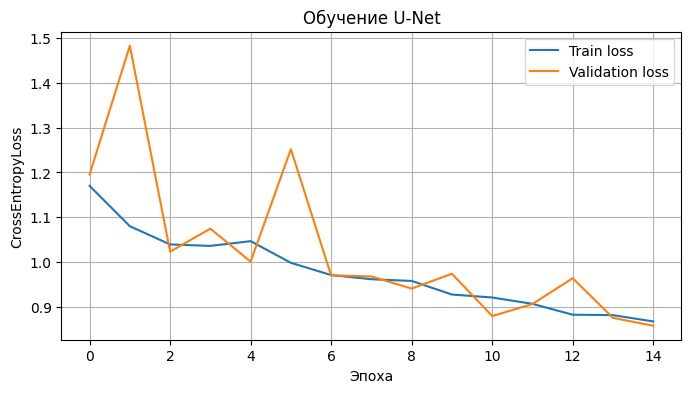

In [8]:
# 5. Обучение U-Net
# Выделяем validation из train_val. Тестовую выборку не используем для подбора модели.
batch_size = 8
val_fraction = 0.15
val_size = max(1, int(len(train_dataset) * val_fraction))
train_size = len(train_dataset) - val_size

split_generator = torch.Generator().manual_seed(SEED)
train_subset, val_subset = random_split(
    train_dataset, [train_size, val_size], generator=split_generator
)

train_loader = DataLoader(
    train_subset, batch_size=batch_size, shuffle=True,
    num_workers=0, pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(
    val_subset, batch_size=batch_size, shuffle=False,
    num_workers=0, pin_memory=torch.cuda.is_available()
)
test_loader = DataLoader(
    test_dataset, batch_size=batch_size, shuffle=False,
    num_workers=0, pin_memory=torch.cuda.is_available()
)

print(f'Train: {len(train_subset)}, Validation: {len(val_subset)}, Test: {len(test_dataset)}')

class_weights = torch.tensor([1.0, 2.0, 3.0, 3.0, 1.5], dtype=torch.float32, device=device)
criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

num_epochs = 15
best_val_loss = float('inf')
best_model_state = None
history = {'train_loss': [], 'val_loss': []}

for epoch in range(num_epochs):
    model.train()
    train_loss_sum = 0.0
    train_pixels = 0

    for imgs, masks in tqdm(train_loader, desc=f'Train {epoch+1}/{num_epochs}'):
        imgs = imgs.to(device, non_blocking=True)
        masks = masks.to(device, non_blocking=True)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()

        batch_pixels = masks.numel()
        train_loss_sum += loss.item() * batch_pixels
        train_pixels += batch_pixels

    avg_train_loss = train_loss_sum / max(train_pixels, 1)

    model.eval()
    val_loss_sum = 0.0
    val_pixels = 0
    with torch.no_grad():
        for imgs, masks in val_loader:
            imgs = imgs.to(device, non_blocking=True)
            masks = masks.to(device, non_blocking=True)
            outputs = model(imgs)
            loss = criterion(outputs, masks)
            batch_pixels = masks.numel()
            val_loss_sum += loss.item() * batch_pixels
            val_pixels += batch_pixels

    avg_val_loss = val_loss_sum / max(val_pixels, 1)
    history['train_loss'].append(avg_train_loss)
    history['val_loss'].append(avg_val_loss)

    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        best_model_state = copy.deepcopy(model.state_dict())

    print(
        f'Epoch {epoch+1:02d}/{num_epochs}: '
        f'train_loss={avg_train_loss:.4f}, val_loss={avg_val_loss:.4f}'
    )

if best_model_state is None:
    raise RuntimeError('Не удалось сохранить состояние лучшей модели.')

model.load_state_dict(best_model_state)
print(f'Восстановлены лучшие веса по validation loss: {best_val_loss:.4f}')

plt.figure(figsize=(8, 4))
plt.plot(history['train_loss'], label='Train loss')
plt.plot(history['val_loss'], label='Validation loss')
plt.xlabel('Эпоха')
plt.ylabel('CrossEntropyLoss')
plt.title('Обучение U-Net')
plt.legend()
plt.grid(True)
plt.show()


Оценка на test:   0%|          | 0/14 [00:00<?, ?it/s]

Pixel Accuracy: 0.7329
IoU класса 0: 0.7786
IoU класса 1: 0.0506
IoU класса 2: 0.2288
IoU класса 3: 0.1994
IoU класса 4: 0.6258
Mean IoU: 0.3766


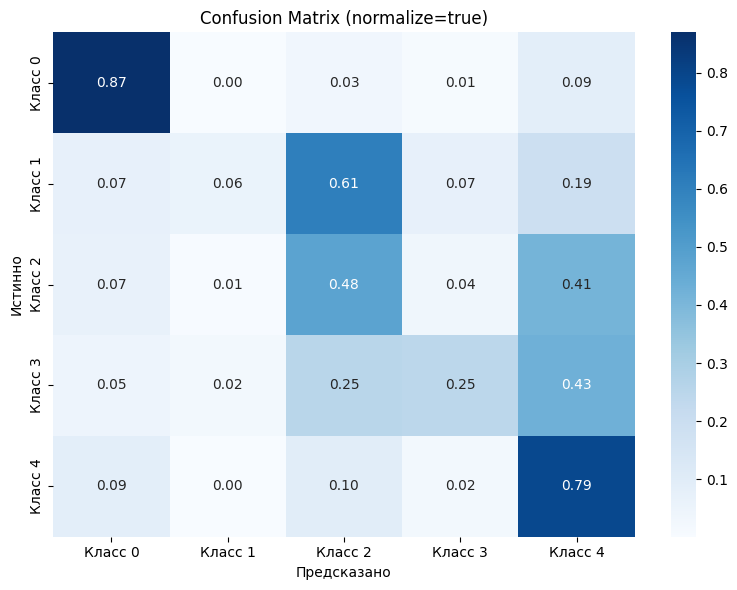

In [9]:
# 6. Итоговая оценка лучшей модели на тестовой выборке
model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for imgs, masks in tqdm(test_loader, desc='Оценка на test'):
        imgs = imgs.to(device)
        masks = masks.to(device)
        outputs = model(imgs)
        preds = outputs.argmax(dim=1)

        all_preds.append(preds.cpu().numpy().ravel())
        all_targets.append(masks.cpu().numpy().ravel())

all_preds = np.concatenate(all_preds)
all_targets = np.concatenate(all_targets)

# Pixel Accuracy
accuracy = (all_preds == all_targets).mean()
print(f'Pixel Accuracy: {accuracy:.4f}')

# IoU по каждому классу и Mean IoU
ious = []
for c in range(NUM_CLASSES):
    pred_c = (all_preds == c)
    target_c = (all_targets == c)
    intersection = np.logical_and(pred_c, target_c).sum()
    union = np.logical_or(pred_c, target_c).sum()
    iou = intersection / union if union > 0 else np.nan
    ious.append(iou)
    print(f'IoU класса {c}: {iou:.4f}' if not np.isnan(iou) else f'IoU класса {c}: нет пикселей')

mean_iou = np.nanmean(ious)
print(f'Mean IoU: {mean_iou:.4f}')

# Confusion matrix по пикселям
cm = confusion_matrix(all_targets, all_preds, labels=list(range(NUM_CLASSES)), normalize='true')
plt.figure(figsize=(8, 6))
sns.heatmap(
    cm, annot=True, fmt='.2f', cmap='Blues',
    xticklabels=[f'Класс {i}' for i in range(NUM_CLASSES)],
    yticklabels=[f'Класс {i}' for i in range(NUM_CLASSES)]
)
plt.xlabel('Предсказано')
plt.ylabel('Истинно')
plt.title('Confusion Matrix (normalize=true)')
plt.tight_layout()
plt.show()


| Новый номер | Цвет исходной маски | Содержание |
|---|---|---|
| **0** | `[0, 0, 0]` (чёрный) | Вода и фон |
| **1** | `[0, 0, 255]` (синий) | Дайверы |
| **2** | `[0, 255, 255]` (голубой) | Обломки и руины |
| **3** | `[255, 255, 0]` (жёлтый) | Рыбы |
| **4** | `[255, 0, 255]` (пурпурный), | Растения, роботы, рифы, дно и камни |

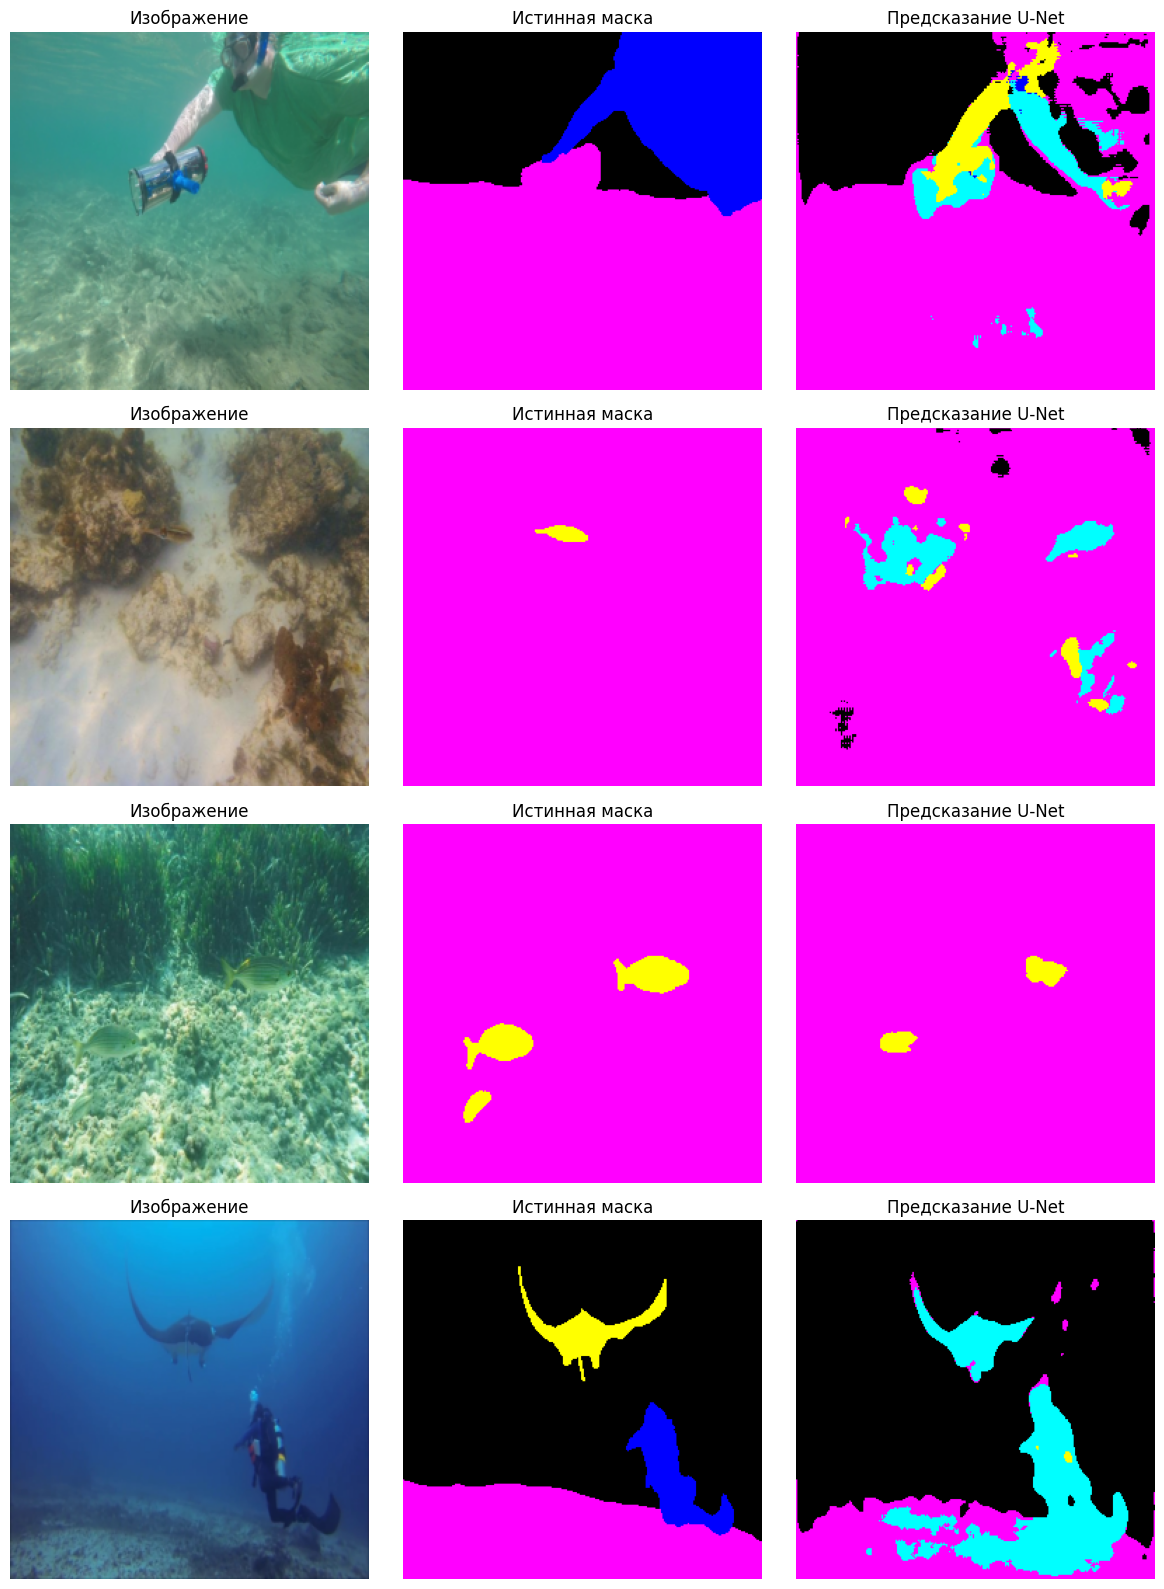

In [10]:
# 7. Визуализация результатов на тестовых изображениях
model.eval()
n_show = min(4, len(test_dataset))
fig, axes = plt.subplots(n_show, 3, figsize=(12, 4*n_show))
if n_show == 1:
    axes = np.expand_dims(axes, axis=0)

with torch.no_grad():
    for i in range(n_show):
        img, mask = test_dataset[i]
        output = model(img.unsqueeze(0).to(device))
        pred = output.argmax(dim=1).squeeze(0).cpu().numpy()

        axes[i, 0].imshow(img.permute(1, 2, 0).numpy())
        axes[i, 0].set_title('Изображение')
        axes[i, 0].axis('off')

        axes[i, 1].imshow(CLASS_COLORS[mask.numpy()])
        axes[i, 1].set_title('Истинная маска')
        axes[i, 1].axis('off')

        axes[i, 2].imshow(CLASS_COLORS[pred])
        axes[i, 2].set_title('Предсказание U-Net')
        axes[i, 2].axis('off')

plt.tight_layout()
plt.show()


In [ ]:
#экспорт в html
import nbformat
from nbconvert import HTMLExporter

notebook = nbformat.read("HW4.ipynb", as_version=4)
html, _ = HTMLExporter().from_notebook_node(notebook)

with open("HW4.html", "w", encoding="utf-8") as f:
    f.write(html)